## Phase 1: Setup, Data Loading & Initial Inspection

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

df = pd.read_csv('../data/raw/reviews.csv')

In [2]:
print(df.shape)
print(df.info())
print(df.isnull().sum())

df['score'] = df['score'].astype(int)
df.to_parquet('../data/processed/reviews_clean.parquet', index=False)

(51385, 5)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 51385 entries, 0 to 51384
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   platform        51385 non-null  object
 1   review_id       51385 non-null  object
 2   published_date  51385 non-null  object
 3   score           51385 non-null  int64 
 4   review_text     51385 non-null  object
dtypes: int64(1), object(4)
memory usage: 2.0+ MB
None
platform          0
review_id         0
published_date    0
score             0
review_text       0
dtype: int64


### Temuan Phase 1: Kualitas & Struktur Data
* **Volume Data:** Dataset awal memiliki 51.385 baris tanpa baris kosong atau missing values.
* **Optimasi:** Data bersih dikonversi ke format `.parquet` untuk mempercepat proses *loading* di tahap berikutnya.

## Phase 2: Analisis Distribusi Skor & Proporsi Sentimen

=== STATISTIK DESKRIPTIF SKOR ===
Mean (Rata-rata)     : 5.00
Median (Nilai Tengah): 4.0
Mode (Modus)         : 10
Std Dev (Sebaran)    : 4.36
Skewness             : 0.05
Kurtosis             : -1.78


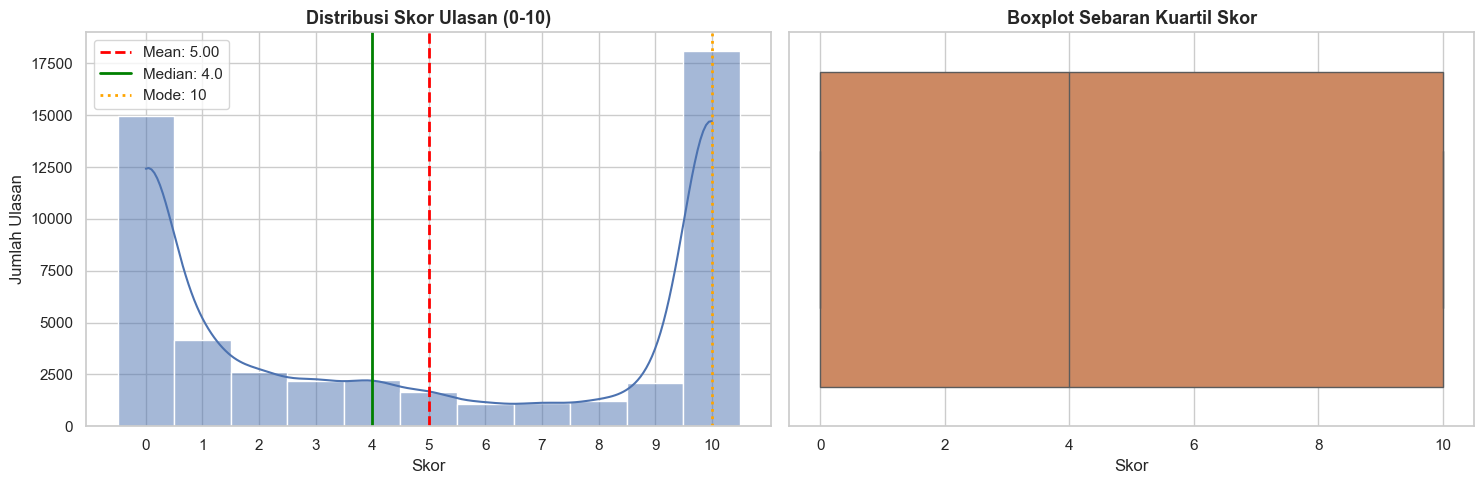

In [3]:
# Membaca data bersih dari Phase 1
df = pd.read_parquet('../data/processed/reviews_clean.parquet')

# Menghitung statistik deskriptif
mean_val = df['score'].mean()
median_val = df['score'].median()
mode_val = df['score'].mode().iloc[0]
std_val = df['score'].std()
skew_val = df['score'].skew()
kurt_val = df['score'].kurt()

print("=== STATISTIK DESKRIPTIF SKOR ===")
print(f"Mean (Rata-rata)     : {mean_val:.2f}")
print(f"Median (Nilai Tengah): {median_val}")
print(f"Mode (Modus)         : {mode_val}")
print(f"Std Dev (Sebaran)    : {std_val:.2f}")
print(f"Skewness             : {skew_val:.2f}")
print(f"Kurtosis             : {kurt_val:.2f}")

# Visualisasi: Histogram + KDE (Kiri) dan Boxplot (Kanan)
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Gunakan axes[0] untuk plot sebelah kiri
sns.histplot(df['score'], bins=11, kde=True, ax=axes[0], color='#4C72B0', discrete=True)
axes[0].axvline(mean_val, color='red', linestyle='--', linewidth=2, label=f'Mean: {mean_val:.2f}')
axes[0].axvline(median_val, color='green', linestyle='-', linewidth=2, label=f'Median: {median_val}')
axes[0].axvline(mode_val, color='orange', linestyle=':', linewidth=2, label=f'Mode: {mode_val}')
axes[0].set_title('Distribusi Skor Ulasan (0-10)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Skor')
axes[0].set_ylabel('Jumlah Ulasan')
axes[0].set_xticks(range(0, 11))
axes[0].legend()

# Gunakan axes[1] untuk plot sebelah kanan
sns.boxplot(x=df['score'], ax=axes[1], color='#DD8452')
axes[1].set_title('Boxplot Sebaran Kuartil Skor', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Skor')

plt.tight_layout()
plt.show()

=== PROPORSI SENTIMEN ===
                 Jumlah Ulasan  Persentase (%)
sentiment_group                               
Negatif (0-3)            23903           46.52
Netral (4-6)              4971            9.67
Positif (7-10)           22511           43.81


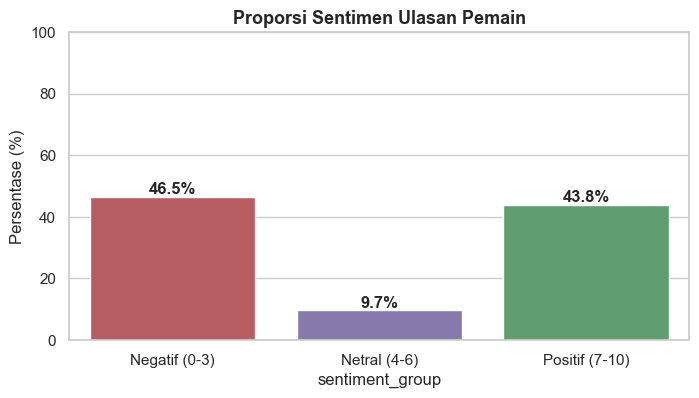

In [4]:
# Mengelompokkan skor ke dalam 3 kategori sentimen
def kelompokkan_sentimen(skor):
    if skor <= 3:
        return 'Negatif (0-3)'
    elif skor <= 6:
        return 'Netral (4-6)'
    else:
        return 'Positif (7-10)'

df['sentiment_group'] = df['score'].apply(kelompokkan_sentimen)

# Menghitung jumlah dan persentase
urutan = ['Negatif (0-3)', 'Netral (4-6)', 'Positif (7-10)']
jumlah = df['sentiment_group'].value_counts().reindex(urutan)
persen = (df['sentiment_group'].value_counts(normalize=True) * 100).reindex(urutan)

ringkasan_sentimen = pd.DataFrame({
    'Jumlah Ulasan': jumlah,
    'Persentase (%)': persen.round(2)
})
print("=== PROPORSI SENTIMEN ===")
print(ringkasan_sentimen)

# Visualisasi Bar Chart Proporsi Sentimen
plt.figure(figsize=(8, 4))
ax = sns.barplot(x=ringkasan_sentimen.index, y=ringkasan_sentimen['Persentase (%)'], hue=ringkasan_sentimen.index, palette=['#C44E52', '#8172B3', '#55A868'], legend=False)
plt.title('Proporsi Sentimen Ulasan Pemain', fontsize=13, fontweight='bold')
plt.ylabel('Persentase (%)')
plt.ylim(0, 100)

for p in ax.patches:
    ax.annotate(f"{p.get_height():.1f}%", 
                (p.get_x() + p.get_width() / 2., p.get_height()), 
                ha='center', va='bottom', fontweight='bold')

plt.show()

### Temuan Phase 2: Pola Sebaran Skor & Sentimen
* **Bentuk Distribusi:** Sebaran skor berbentuk **bimodal (menumpuk di 0 dan 10)** dengan modus berada di skor **10** diikuti skor **0**.
* **Ukuran Pemusatan:** Nilai rata-rata (*mean*) adalah **5.00**, sedangkan nilai tengah (*median*) adalah **4.0**. Nilai *skewness* sebesar **0.05** menunjukkan distribusi hampir simetris secara keseluruhan, sementara *kurtosis* sebesar **-1.78** mengonfirmasi bentuk distribusi yang terbelah ekstrem ke dua ujung.
* **Segmentasi Sentimen:** Ulasan terpolarisasi tajam dan didominasi kategori **Negatif (0–3)** sebesar **46.5%**, hampir berimbang dengan **Positif (7–10)** sebesar **43.8%**, sedangkan **Netral (4–6)** hanya **9.7%**.

## Phase 3: Analisis Panjang Ulasan vs Skor

=== RATA-RATA & MEDIAN PANJANG KATA PER SENTIMEN ===
                  mean  median   max
sentiment_group                     
Negatif (0-3)     72.9    39.0  1364
Netral (4-6)     118.3    66.0   972
Positif (7-10)    67.4    35.0   992

Korelasi Skor vs Jumlah Kata: -0.026


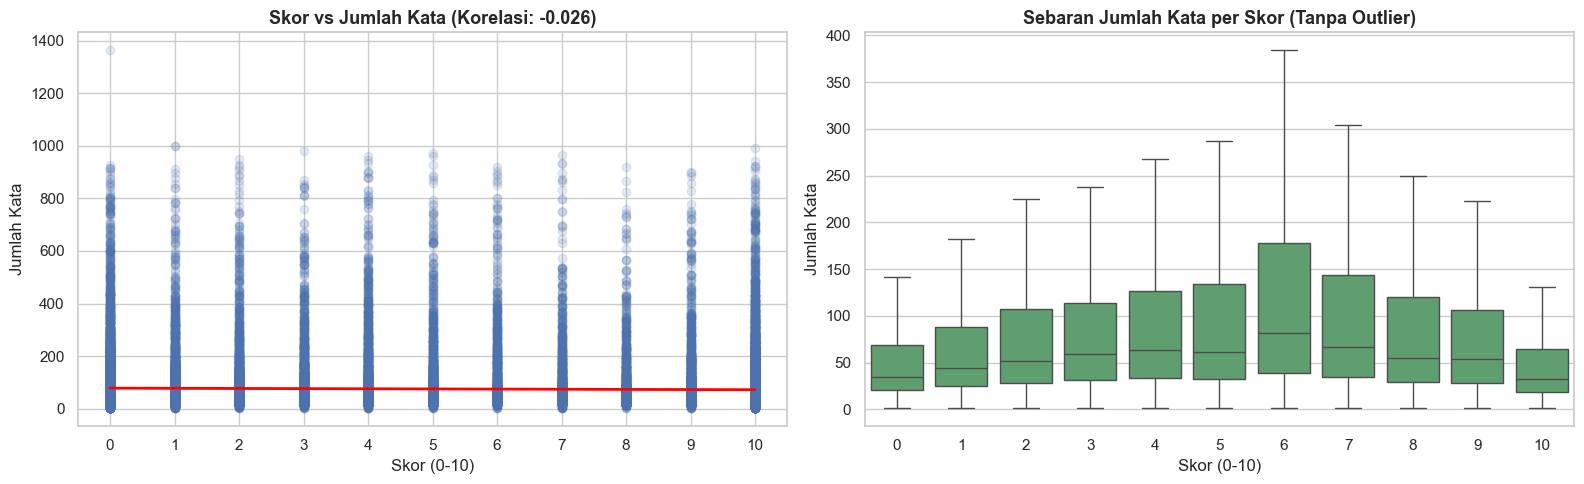

In [6]:
# 1. Membuat kolom jumlah karakter dan jumlah kata
df['text_length'] = df['review_text'].str.len()
df['word_count'] = df['review_text'].str.split().str.len()

# 2. Statistik panjang kata per kelompok sentimen
print("=== RATA-RATA & MEDIAN PANJANG KATA PER SENTIMEN ===")
print(df.groupby('sentiment_group', observed=False)['word_count'].agg(['mean', 'median', 'max']).round(1))

# 3. Menghitung korelasi Pearson antara skor dan jumlah kata
korelasi = df['score'].corr(df['word_count'])
print(f"\nKorelasi Skor vs Jumlah Kata: {korelasi:.3f}")

# 4. Visualisasi: Scatter + Trendline (Kiri) dan Boxplot per Skor (Kanan)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

# Plot kiri: Scatter plot dengan garis regresi (menggunakan ax1)
sns.regplot(data=df, x='score', y='word_count', ax=ax1,
            scatter_kws={'alpha': 0.15, 'color': '#4C72B0'},
            line_kws={'color': 'red', 'linewidth': 2})
ax1.set_title(f'Skor vs Jumlah Kata (Korelasi: {korelasi:.3f})', fontsize=13, fontweight='bold')
ax1.set_xlabel('Skor (0-10)')
ax1.set_ylabel('Jumlah Kata')
ax1.set_xticks(range(0, 11))

# Plot kanan: Boxplot panjang kata di tiap skor (menggunakan ax2)
sns.boxplot(data=df, x='score', y='word_count', ax=ax2, showfliers=False, color='#55A868')
ax2.set_title('Sebaran Jumlah Kata per Skor (Tanpa Outlier)', fontsize=13, fontweight='bold')
ax2.set_xlabel('Skor (0-10)')
ax2.set_ylabel('Jumlah Kata')

plt.tight_layout()
plt.show()

### Temuan Phase 3: Hubungan Skor dengan Panjang Ulasan
* **Korelasi Linear Mendekati Nol (`-0.026`):** Tidak ditemukan hubungan linear langsung antara skor dan panjang tulisan karena polanya berbentuk **non-linear**.
* **Pola pada Boxplot:** Ulasan terpanjang justru ditulis oleh kelompok **Netral (4–6)** dengan rata-rata **118.3 kata**.
* **Kutub Ekstrem Cenderung Singkat:** Pemberi skor **Negatif (0–3)** rata-rata hanya menulis **72.9 kata** dan **Positif (7–10)** sebesar **67.4 kata**. Ini menunjukkan skor 0 dan 10 didominasi reaksi emosional singkat, sedangkan skor menengah berisi kritik konstruktif yang lebih terperinci.

## Phase 4: Analisis Teks Sederhana (Bahasa Non-ASCII, Topik & Frekuensi Kata)

Total Ulasan Mengandung Karakter Non-ASCII: 40.03%

=== PERSENTASE NON-ASCII PER SKOR (%) ===
score
0     32.36
1     34.25
2     35.00
3     35.13
4     40.11
5     41.34
6     43.89
7     45.71
8     45.16
9     45.71
10    47.29
Name: True, dtype: float64


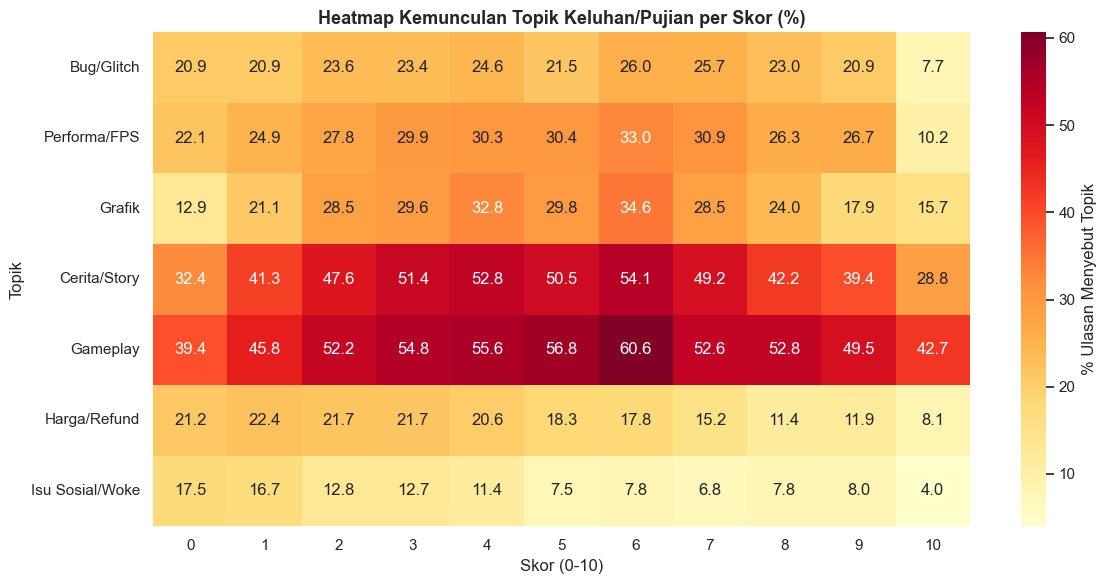


=== TOP 15 KATA PALING SERING MUNCUL ===
review_text
story         16069
world          9919
good           8542
people         8330
feels          8272
graphics       8117
about          7788
fps            7494
juego          7394
play           7217
characters     7205
time           7092
cant           7043
years          7002
woke           6990
Name: count, dtype: int64


In [9]:
# 1. Deteksi kasar karakter non-ASCII (Mandarin, Arab, Sirilik, dll.)
df['is_non_ascii'] = df['review_text'].str.contains(r'[^\x00-\x7F]', regex=True)
proporsi_non_ascii = df['is_non_ascii'].mean() * 100
print(f"Total Ulasan Mengandung Karakter Non-ASCII: {proporsi_non_ascii:.2f}%")

non_ascii_per_skor = pd.crosstab(df['score'], df['is_non_ascii'], normalize='index') * 100
print("\n=== PERSENTASE NON-ASCII PER SKOR (%) ===")
print(non_ascii_per_skor[True].round(2))

# 2. Keyword counting per topik (sesuaikan kata kunci jika perlu)
topik_keywords = {
    'Bug/Glitch': 'bug|glitch|crash|broken|freeze',
    'Performa/FPS': 'fps|lag|frame|stutter|optimize|performance',
    'Grafik': 'graphic|visual|texture|resolution',
    'Cerita/Story': 'story|plot|ending|character|mission',
    'Gameplay': 'gameplay|combat|driving|ai|control|mechanic',
    'Harga/Refund': 'price|money|refund|worth|pay|buy',
    'Isu Sosial/Woke': 'woke|agenda|politic|DEI'
}

for nama_topik, pattern in topik_keywords.items():
    df[nama_topik] = df['review_text'].str.contains(pattern, case=False, regex=True)

# 3. Visualisasi Heatmap: Topik vs Skor
topik_cols = list(topik_keywords.keys())
heatmap_data = df.groupby('score')[topik_cols].mean() * 100

plt.figure(figsize=(12, 6))
sns.heatmap(heatmap_data.T, annot=True, fmt=".1f", cmap="YlOrRd", cbar_kws={'label': '% Ulasan Menyebut Topik'})
plt.title('Heatmap Kemunculan Topik Keluhan/Pujian per Skor (%)', fontsize=13, fontweight='bold')
plt.xlabel('Skor (0-10)')
plt.ylabel('Topik')
plt.tight_layout()
plt.show()

# 4. Frekuensi 15 kata teratas (tanpa NLP, hapus stopwords manual)
stopwords = {
    'the', 'and', 'to', 'of', 'a', 'is', 'in', 'it', 'this', 'for', 'game', 
    'i', 'that', 'with', 'on', 'was', 'but', 'as', 'are', 'have', 'be', 
    'not', 'you', 'they', 'so', 'all', 'its', 'my', 'just', 'like', 'one', 'at', 'from',
    'gta', 'rockstar', 'games', 'que', 'what', 'has', 'more', 'even', 'dont', 'can'
}

kata_bersih = (
    df['review_text']
    .str.lower()
    .str.replace(r'[^\w\s]', '', regex=True)
    .str.split()
    .explode()
)
kata_bersih = kata_bersih[~kata_bersih.isin(stopwords) & (kata_bersih.str.len() > 2)]

print("\n=== TOP 15 KATA PALING SERING MUNCUL ===")
print(kata_bersih.value_counts().head(15))

### Temuan Phase 4: Proporsi Bahasa Non-ASCII, Topik Utama & Frekuensi Kata
* **Komunitas Non-ASCII Sangat Suportif:** Sebanyak **40.03%** ulasan mengandung karakter non-ASCII. Proporsinya justru meningkat konsisten dari **32.36% pada skor 0** menjadi **47.29% pada skor 10**, didorong oleh besarnya komunitas pemain berbahasa Spanyol atau Portugis seperti yang terlihat dari tingginya kemunculan kata *"juego"* sebanyak 7.394 kali.
* **Pemicu Skor 0 vs Skor 10 pada Heatmap:**
  * **Gameplay sebesar 39.4%** dan **Cerita/Story sebesar 32.4%** menjadi topik paling banyak disorot pada skor 0, diikuti masalah teknis **Performa/FPS sebesar 22.1%**, **Harga/Refund sebesar 21.2%**, dan **Bug/Glitch sebesar 20.9%**.
  * Topik **Isu Sosial/Woke** menunjukkan korelasi negatif paling tajam karena memuncak di **skor 0 sebesar 17.5%** dan **skor 1 sebesar 16.7%**, lalu terus turun hingga titik terendah di **skor 10 sebesar 4.0%**.
  * Pada **skor 10**, pembahasan keluhan teknis turun drastis dengan **Bug/Glitch hanya 7.7%** dan **Performa/FPS sebesar 10.2%**.
* **Evaluasi Terlengkap di Skor Menengah:** Kemunculan hampir seluruh topik memuncak pada **skor 6**, yaitu **Gameplay sebesar 60.6%**, **Cerita/Story sebesar 54.1%**, dan **Grafik sebesar 34.6%**. Hal ini mengonfirmasi temuan Phase 3 bahwa ulasan skor menengah menilai game secara paling objektif dan menyeluruh.
* **Kata Kunci Dominan:** Setelah penyaringan *stopwords*, kata yang paling mendominasi pembicaraan adalah *story* sebanyak 16.069 kali, *world* sebanyak 9.919 kali, *good* sebanyak 8.542 kali, *graphics* sebanyak 8.117 kali, *fps* sebanyak 7.494 kali, dan *woke* sebanyak 6.990 kali.

## Phase 5: Bedah Review Ekstrem, Skor 0 vs Skor 10

In [10]:
# Pastikan daftar lengkap 7 topik sudah siap
topik_cols_lengkap = ['Bug/Glitch', 'Performa/FPS', 'Grafik', 'Cerita/Story', 'Gameplay', 'Harga/Refund', 'Isu Sosial/Woke']

# 1. Filter data khusus untuk skor ekstrem (0 dan 10)
df_ekstrem = df[df['score'].isin([0, 10])].copy()

# 2. Membuat tabel perbandingan metrik kuantitatif
metrik_cols = ['word_count', 'is_non_ascii'] + topik_cols_lengkap
perbandingan = df_ekstrem.groupby('score')[metrik_cols].mean()

# Ubah kolom boolean menjadi persentase (%)
persen_cols = ['is_non_ascii'] + topik_cols_lengkap
perbandingan[persen_cols] = perbandingan[persen_cols] * 100
perbandingan['total_review'] = df_ekstrem.groupby('score').size()

print("=== PERBANDINGAN PROFIL SKOR 0 VS SKOR 10 ===")
print(perbandingan.round(1).T)

# 3. Sampling manual 5 ulasan acak per kelompok untuk validasi kualitatif
print("\n=== 5 SAMPEL ULASAN SKOR 0 ===")
for i, teks in enumerate(df[df['score'] == 0]['review_text'].sample(5, random_state=42), 1):
    teks_rapi = teks[:220].replace('\n', ' ')
    print(f"{i}. {teks_rapi}...")

print("\n=== 5 SAMPEL ULASAN SKOR 10 ===")
for i, teks in enumerate(df[df['score'] == 10]['review_text'].sample(5, random_state=42), 1):
    teks_rapi = teks[:220].replace('\n', ' ')
    print(f"{i}. {teks_rapi}...")

=== PERBANDINGAN PROFIL SKOR 0 VS SKOR 10 ===
score                 0        10
word_count          63.7     59.0
is_non_ascii        32.4     47.3
Bug/Glitch          20.9      7.7
Performa/FPS        22.1     10.2
Grafik              12.9     15.7
Cerita/Story        32.4     28.8
Gameplay            39.4     42.7
Harga/Refund        21.2      8.1
Isu Sosial/Woke     17.5      4.0
total_review     14956.0  18097.0

=== 5 SAMPEL ULASAN SKOR 0 ===
1. there’s literally nothing to do besides ****, jason is sexy so it gets a 2 from me. the opening missions are unbearable, the gameplay mechanics are terrible, and nothing about the experience makes me want to keep playing...
2. Metacritic removed the access to my account with my honest review so this time I am giving it a flat ZERO cause that's what they deserve!  SHAME ON ROCKSTAR AND METACRITIC FOR REMOVING HONEST REVIEWS JUST CAUSE THEY CANT...
3. Es un juego muy simple de disparos, no tiene nada especial, esta lleno de bugs y de glitche

### Temuan Phase 5: Validasi Kualitatif Skor 0 vs Skor 10
* **Perbandingan Kuantitatif Dua Kutub:** Dari total **14.956 ulasan skor 0** dan **18.097 ulasan skor 10**, rata-rata panjang tulisan keduanya relatif berimbang dan singkat, yakni **63.7 kata pada skor 0** dibandingkan **59.0 kata pada skor 10**. Namun secara topik, ulasan skor 0 mencatat lonjakan keluhan teknis dan nilai ekonomi yang jauh lebih tinggi, yaitu **Performa/FPS sebesar 22.1% vs 10.2%**, **Harga/Refund sebesar 21.2% vs 8.1%**, **Bug/Glitch sebesar 20.9% vs 7.7%**, serta **Isu Sosial/Woke sebesar 17.5% vs 4.0%**.
* **Tiga Motif Utama di Balik Skor 0:** Pembacaan sampel acak mengungkap bahwa pemberian skor 0 didorong oleh tiga pola keluhan, yaitu kekecewaan terhadap desain misi dan mekanik *gameplay* yang dianggap membosankan, penolakan terhadap unsur *woke* maupun rasa tidak sebanding dengan harga beli, serta aksi protes pemain terhadap penghapusan ulasan sebelumnya di platform Metacritic.
* **Dominasi Antusiasme Multibahasa pada Skor 10:** Sebanyak **47.3%** ulasan skor 10 mengandung karakter non-ASCII. Sampel acak menunjukkan tingginya pujian dari pemain berbahasa Spanyol, Portugis, dan Italia yang menyoroti kemegahan dunia terbuka Leonida dan Vice City, kualitas grafik, serta cerita karakter Jason dan Lucia.